In [66]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from src.features import calcular_antiguedad_autor, crear_codificador_categorico, transformar_features_categoricas
from src.modelos import MLP_regresion, MLP_clasificacion
from src.utils import df_features_to_numpy, df_target_to_numpy, run_experiment_pytorch_clasificacion, run_experiment_pytorch_regresion, permutation_importance_pytorch, run_grid_search_pytorch_clasificacion, grid_search_xgb_aceptacion, evaluar_modelo_xgb_aceptacion
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion, evaluar_metricas_clasificacion_binaria
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf, plot_feature_importance_pytorch

# Cargo los datasets

In [68]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list_test = []
for chunk in chunks_test:
    chunk_list_test.append(chunk)
df_test = pd.concat(chunk_list_test, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list_val = []
for chunk in chunks_val:
    chunk_list_val.append(chunk)
df_val = pd.concat(chunk_list_val, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list_train = []
for chunk in chunks_train:
    chunk_list_train.append(chunk)
df_train = pd.concat(chunk_list_train, ignore_index=True)

# Preparacion de los datos
En primer lugar, unifico train y val para reentrenar con estos datos. 

In [69]:
df_dev = pd.concat([df_train, df_val], ignore_index=True)

# MODELO CLASIFICACION BINARIA

In [70]:
def clasificar_aceptacion(rating):
    return rating > 3.5
    
df_dev["aceptado"] = df_dev["average_rating"].apply(clasificar_aceptacion)
df_test["aceptado"] = df_test["average_rating"].apply(clasificar_aceptacion)

In [71]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features_base = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos

dfs = [df_dev, df_test]
y_dev_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_dev_clasificacion, y_test_clasificacion = df_target_to_numpy("aceptado", dfs)
X_dev, X_test = df_features_to_numpy(features_base, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_dev_scaled = scaler.fit_transform(X_dev)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_sub, _, y_sub_regresion, _, y_sub_clasificacion, _ = train_test_split(X_dev_scaled, y_dev_clasificacion, y_dev_clasificacion, train_size=100000, stratify=y_dev_clasificacion, random_state=42)

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {1: 300000} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_dev_undersampling, y_dev_undersampling = undersampling.fit_resample(X_dev_scaled, y_dev_clasificacion) 

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {1: 56150}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Mejor precision CV: 0.7317021505046216


,Train,Validation
Accuracy,0.771293,0.791237
Precision,0.847741,0.891698
Recall,0.861423,0.855797
F1,0.854527,0.873379


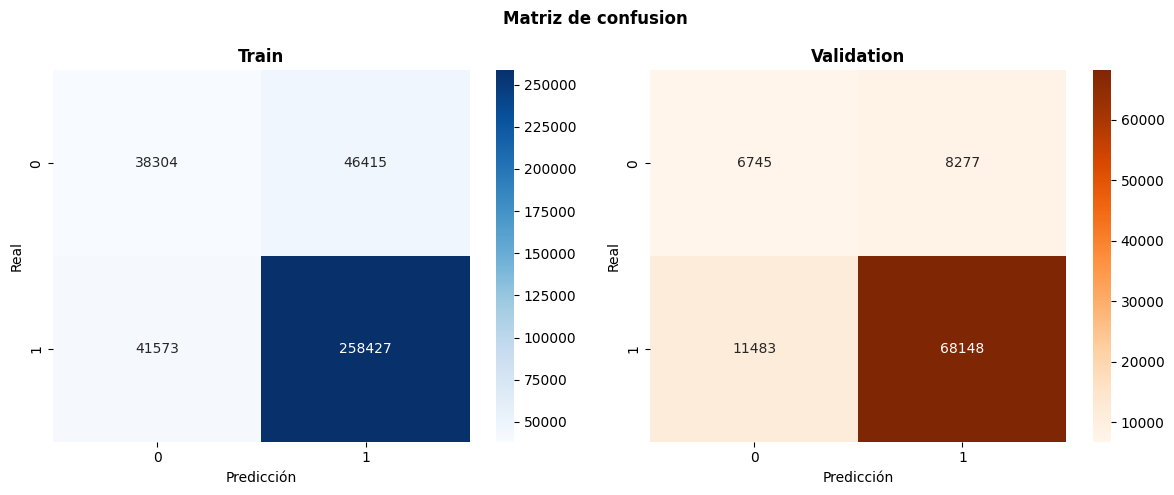

In [ ]:
pesos_undersampling_cost = {0:2, 1:1}
mejores_parametros = grid_search_xgb_aceptacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion, metricas_dev_xgb, metricas_test_xgb = evaluar_modelo_xgb_aceptacion(mejores_parametros, pesos_undersampling_cost, X_dev_undersampling, y_dev_undersampling, X_test_scaled, y_test_clasificacion)

# PREPARO LOS DATASETS PARA USAR FEATURES AVANZADAS

In [76]:
#features que no van a ser usadas
df_dev = df_dev.drop(columns = ["description", "title", "language_code", "ratings_count", "authors", "format_group", "genres", "title_key", "title_text"])
df_test = df_test.drop(columns = ["description", "title", "language_code", "ratings_count", "authors", "format_group", "genres", "title_key", "title_text"])

#cargo los embeddings
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")
descripcion_emb_test = np.load("descripcion_emb_test.npy")

descripcion_emb_dev = np.concatenate([descripcion_emb_train, descripcion_emb_val], axis = 0)
descripcion_columnas = [ f"description_emb_{i}" for i in range(descripcion_emb_test.shape[1])]
descripcion_emb_dev_df = pd.DataFrame(descripcion_emb_dev, columns = descripcion_columnas,index=df_dev.index)
descripcion_emb_test_df = pd.DataFrame(descripcion_emb_test, columns = descripcion_columnas, index = df_test.index)

df_dev = df_dev.join(descripcion_emb_dev_df)
df_test = df_test.join(descripcion_emb_test_df)

#calculo otras features
df_dev = calcular_antiguedad_autor(df_dev)
df_test = calcular_antiguedad_autor(df_test)
features_avanzadas = (features_base + descripcion_columnas + ["author_antiguedad"])

In [77]:
#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_dev, df_test]

y_dev_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_dev_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)

df_dev = df_dev.drop(columns = ["average_rating", "estrellas"])
df_test = df_test.drop(columns = ["average_rating", "estrellas"])

In [78]:
columnas_categor = ["author_id_principal", "publisher"]

#Dev
codificador_regresion = crear_codificador_categorico(df_dev, y_dev_regresion, columnas_categor, "average_rating")
X_dev_regresion = transformar_features_categoricas(df_dev, codificador_regresion)
X_test_regresion = transformar_features_categoricas(df_test, codificador_regresion)
X_dev_regresion = X_dev_regresion.drop(columns = columnas_categor)
X_test_regresion = X_test_regresion.drop(columns = columnas_categor)

#Test
codificador_clasificacion = crear_codificador_categorico(df_dev, y_dev_clasificacion, columnas_categor, "estrellas")
X_dev_clasificacion = transformar_features_categoricas(df_dev, codificador_clasificacion)
X_test_clasificacion = transformar_features_categoricas(df_test, codificador_clasificacion)
X_dev_clasificacion = X_dev_clasificacion.drop(columns = columnas_categor)
X_test_clasificacion = X_test_clasificacion.drop(columns = columnas_categor)

In [79]:
#Me guardo los nombres de las features para cuando hagamos las feature importance:
columnas_regresion = X_dev_regresion.columns.tolist()
columnas_clasificacion = X_dev_clasificacion.columns.tolist()

In [ ]:
#Para regresion:
scaler_regresion = StandardScaler()
X_dev_regresion = pd.DataFrame(scaler_regresion.fit_transform(X_dev_regresion), columns = columnas_regresion, index = X_dev_regresion.index)
X_test_regresion = pd.DataFrame(scaler_regresion.transform(X_test_regresion), columns = columnas_regresion, index = X_test_regresion.index)
X_dev_regresion = X_dev_regresion.to_numpy()
X_test_regresion = X_test_regresion.to_numpy()

#Para clasificacion:
scaler_clasificacion = StandardScaler()
X_dev_clasificacion = pd.DataFrame(scaler_clasificacion.fit_transform(X_dev_clasificacion), columns=columnas_clasificacion, index = X_dev_clasificacion.index)
X_test_clasificacion = pd.DataFrame(scaler_clasificacion.transform(X_test_clasificacion), columns = columnas_clasificacion, index = X_test_clasificacion.index)
X_dev_clasificacion = X_dev_clasificacion.to_numpy()
X_test_clasificacion = X_test_clasificacion.to_numpy()

In [ ]:
X_sub_regresion, _, y_sub_regresion, _ = train_test_split(X_dev_regresion, y_dev_regresion, train_size = 100000, random_state = 42)
X_sub_clasificacion, _, y_sub_clasificacion, _ = train_test_split(X_dev_clasificacion, y_dev_clasificacion, train_size = 100000, stratify = y_dev_clasificacion, random_state = 42)

parametros_grid_search_xgb = {
    "n_estimators": [200, 300],
    "max_depth": [5, 7],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2],
    "lr": [0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

# CLASIFICACION MULTICLASE

In [ ]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {4: 379000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_dev_undersampling, y_dev_undersampling = undersampling.fit_resample(X_dev_clasificacion, y_dev_clasificacion) 

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {4: 50000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub_clasificacion, y_sub_clasificacion) 

In [86]:
pesos_undersampling_cost = {1:8, 2:10, 3:2, 4:1, 5:3}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout = {dropout}, lr = {lr}, activacion = {activacion.__name__}")
                modelo = MLP_clasificacion(input_size = X_sub_undersampling.shape[1], hidden_layers = capas_ocultas, n_classes = 5, activation = activacion, dropout = dropout).to(device)
                f1 = run_grid_search_pytorch_clasificacion(modelo = modelo, learning_rate = lr, model_name = "MLP Clasificacion", X_train = X_sub_undersampling, y_train = y_sub_clasificacion_undersampling, X_val = X_test_clasificacion, y_val = y_test_clasificacion, device = device, epochs = 30, pesos = pesos_undersampling_cost)
                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout = 0.0, lr = 0.001, activacion = ReLU


PyTorch: 100%|██████████| 30/30 [00:49<00:00,  1.66s/epoca, epoch=30]


Probando: [128, 64], dropout = 0.0, lr = 0.001, activacion = LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:59<00:00,  1.98s/epoca, epoch=30]


Probando: [128, 64], dropout = 0.0, lr = 0.0001, activacion = ReLU


...

Probando: [256, 128, 64], dropout = 0.2, lr = 0.0001, activacion = ReLU


PyTorch: 100%|██████████| 30/30 [00:55<00:00,  1.85s/epoca, epoch=30]


Probando: [256, 128, 64], dropout = 0.2, lr = 0.0001, activacion = LeakyReLU


PyTorch: 100%|██████████| 30/30 [01:00<00:00,  2.00s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [256, 128], 'dropout': 0.2, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch: 100%|██████████| 100/100 [09:39<00:00,  5.80s/epoca, epoch=100]


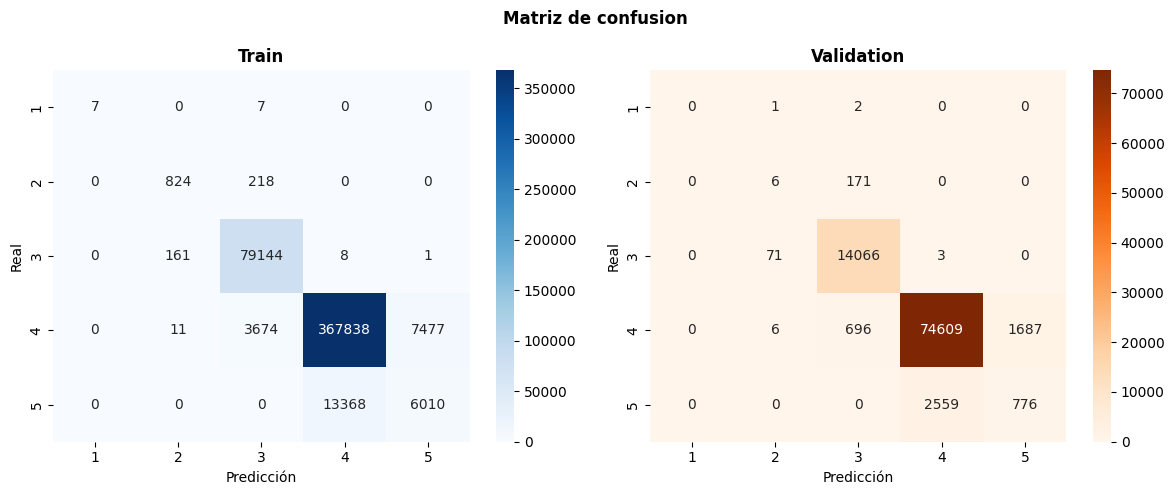

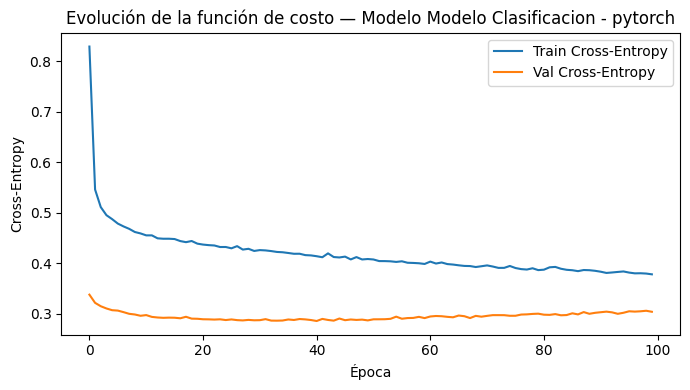

,Train,Validation
Accuracy,0.947937,0.945105
Precision,0.838170,0.459021
Recall,0.713868,0.446064
F1_score,0.756738,0.449822


In [87]:
modelo_clasificacion = MLP_clasificacion(input_size = X_dev_undersampling.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_dev, metricas_test = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_dev_undersampling, y_dev_undersampling, X_test_clasificacion, y_test_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_dev, metricas_test, ["Accuracy", "Precision", "Recall", "F1_score"])
display(tabla_metricas_mlp_clasificacion_undersampling)

# REGRESION

In [88]:
XGBoostGridSearchRegresion = XGBRegressor(objective = "reg:squarederror", device = "cuda", tree_method = "hist", random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = 1, verbose = 1)
grid.fit(X_sub_regresion, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits


c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:11:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:11:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:11:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [20

Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Mejor R² CV: 0.5918762544228539


In [89]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", device = "cuda", tree_method = "hist", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_dev_regresion, y_dev_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_dev_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_dev_regresion)
y_pred_test_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_test_regresion)

metricas_dev = evaluar_metricas_regresion(y_pred_dev_modeloXGBoostRegresion, y_dev_regresion)
metricas_test = evaluar_metricas_regresion(y_pred_test_modeloXGBoostRegresion, y_test_regresion)
tabla_metricas_xgboost_regresion = tabla_metricas(metricas_dev, metricas_test, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_xgboost_regresion)

c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:14:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:14:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


,Train,Validation
MSE,0.052828,0.058737
RMSE,0.229843,0.242358
MAE,0.182768,0.194090
R²,0.626628,0.590012
